# PA：使用KNN完成鸢尾花分类

**姓名：** 请填写　　**班级：** 请填写

本次PA重点考查参数比较、交叉验证、标准化与决策边界。请依次运行并完成所有标有 **TODO** 的位置。

## 使用规则

- 任务1的循环代码必须独立完成，不使用生成式AI。
- 可以查阅教师材料和官方文档。
- 提交前运行全部单元，保留代码、文字、输出和图像。
- 拓展任务如使用AI，必须在最后说明。

## 0. 环境检查

先运行下面的代码。如果出现缺少库的错误，请立即告诉老师。

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

print("NumPy version:", np.__version__)
print("scikit-learn version:", sklearn.__version__)
print("环境检查完成。")

NumPy version: 2.5.5
scikit-learn version: 1.9.1
环境检查完成。


## 1. 认识数据

鸢尾花数据集包含150个样本、4个特征和3个类别。下面的代码已经给出。

In [6]:
iris = load_iris()
X = iris.data
y = iris.target

print("X的形状：", X.shape)
print("y的形状：", y.shape)
print("特征名称：", iris.feature_names)
print("类别名称：", iris.target_names)
print("前5个样本：\n", X[:5])

X的形状： (150, 4)
y的形状： (150,)
特征名称： ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
类别名称： ['setosa' 'versicolor' 'virginica']
前5个样本：
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]


## 2. 单次训练集/测试集划分

先将70%的数据作为训练集，30%的数据作为测试集。`stratify=y`使三个类别在训练集和测试集中的比例基本一致。

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("训练集大小：", len(X_train))
print("测试集大小：", len(X_test))

训练集大小： 105
测试集大小： 45


### 2.1 先运行一个 k=5 的KNN

下面是一个完整示例。请先运行并确认代码能够正常工作。

In [8]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("k=5时的测试集准确率：", accuracy_score(y_test, y_pred))

k=5时的测试集准确率： 0.9777777777777777


### 2.2 必做：比较 k=1～30

**TODO：**仿照上面的示例，补全循环。把每个 `k` 对应的测试集准确率依次加入 `test_accuracies`。此部分必须独立完成。

In [9]:
k_values = list(range(1, 31))
test_accuracies = []

for k in k_values:
    # TODO 1：建立n_neighbors=k的KNN模型
    model = KNeighborsClassifier(n_neighbors=k)
    # TODO 2：使用训练集训练模型
    model.fit(X_train, y_train)
    # TODO 3：预测测试集
    y_pred = model.predict(X_test)
    # TODO 4：计算准确率，并加入test_accuracies
    test_accuracies.append(accuracy_score(y_test, y_pred))

print(test_accuracies)

[0.9333333333333333, 0.9111111111111111, 0.9555555555555556, 0.9555555555555556, 0.9777777777777777, 0.9333333333333333, 0.9555555555555556, 0.9333333333333333, 0.9555555555555556, 0.9555555555555556, 0.9333333333333333, 0.9333333333333333, 0.9333333333333333, 0.9333333333333333, 0.9555555555555556, 0.9555555555555556, 0.9555555555555556, 0.9555555555555556, 0.9555555555555556, 0.9333333333333333, 0.9555555555555556, 0.9333333333333333, 0.9555555555555556, 0.9333333333333333, 0.9333333333333333, 0.9555555555555556, 0.9333333333333333, 0.9111111111111111, 0.9111111111111111, 0.9111111111111111]


下面的绘图代码已经给出。只有在上一单元正确得到30个准确率后才能运行。

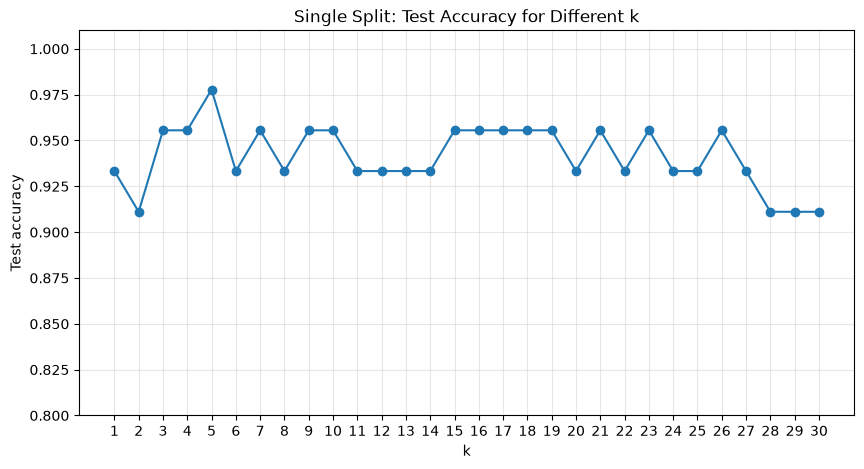

最高测试集准确率： 0.9777777777777777
达到最高准确率的k： [5]


In [10]:
plt.figure(figsize=(10, 5))
plt.plot(k_values, test_accuracies, marker="o")
plt.xlabel("k")
plt.ylabel("Test accuracy")
plt.title("Single Split: Test Accuracy for Different k")
plt.xticks(k_values)
plt.ylim(0.8, 1.01)
plt.grid(alpha=0.3)
plt.show()

best_accuracy = max(test_accuracies)
best_k_single = [k for k, acc in zip(k_values, test_accuracies) if acc == best_accuracy]
print("最高测试集准确率：", best_accuracy)
print("达到最高准确率的k：", best_k_single)

### 2.3 分析

**TODO：请根据自己的运行结果回答。不要只写一般性结论。**

1. 哪些k取得了最高测试集准确率？

答：k=5

2. k较小时有什么特点？k较大时有什么特点？

答：k较小时，模型只考虑最近的几个邻居，准确率随k变化剧烈。比如在k=2时模型的准确率为0.91，在k=3时模型的准确率又直接增长到0.956。而k较大时，模型考虑的范围更大，准确率的变化更为平缓。比如在k=28，29，30时模型的准确率都为0.91。

3. 仅根据这一次数据划分选择k，可能有什么问题？

答：只按一种可能性划分可能受到偶然性的影响，比如现在的k=5时最高，为0.978，换一种划分方式之后最高的k可能就不再是k=5了。

## 3. 5折交叉验证

单次划分的结果可能受到偶然性的影响。下面使用5折分层交叉验证。我们只在训练集上比较参数，测试集留到最后使用。

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

example_model = KNeighborsClassifier(n_neighbors=5)
example_scores = cross_val_score(
    example_model, X_train, y_train, cv=cv, scoring="accuracy"
)

print("5次验证准确率：", example_scores)
print("平均准确率：", example_scores.mean())
print("标准差：", example_scores.std())

5次验证准确率： [0.95238095 1.         0.95238095 1.         0.9047619 ]
平均准确率： 0.9619047619047618
标准差： 0.03563483225498992


### 3.1 必做：用交叉验证比较 k=1～30

**TODO：**补全下面两处。每个k都要记录5折准确率的平均值和标准差。

In [12]:
cv_mean_scores = []
cv_std_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    # TODO：将scores的平均值加入cv_mean_scores
    cv_mean_scores.append(scores.mean())
    # TODO：将scores的标准差加入cv_std_scores
    cv_std_scores.append(scores.std())

print("平均准确率：", cv_mean_scores)
print("标准差：", cv_std_scores)

平均准确率： [np.float64(0.9619047619047618), np.float64(0.9619047619047618), np.float64(0.9619047619047618), np.float64(0.9428571428571428), np.float64(0.9619047619047618), np.float64(0.9619047619047618), np.float64(0.9714285714285713), np.float64(0.9714285714285713), np.float64(0.9714285714285713), np.float64(0.9523809523809523), np.float64(0.9714285714285715), np.float64(0.9523809523809523), np.float64(0.9714285714285713), np.float64(0.9428571428571428), np.float64(0.9428571428571428), np.float64(0.9333333333333333), np.float64(0.9333333333333333), np.float64(0.9428571428571428), np.float64(0.9523809523809523), np.float64(0.9619047619047618), np.float64(0.9428571428571428), np.float64(0.9428571428571427), np.float64(0.9238095238095237), np.float64(0.9238095238095237), np.float64(0.9047619047619048), np.float64(0.9333333333333332), np.float64(0.9142857142857143), np.float64(0.8952380952380953), np.float64(0.8952380952380953), np.float64(0.9142857142857143)]
标准差： [np.float64(0.0356348322549

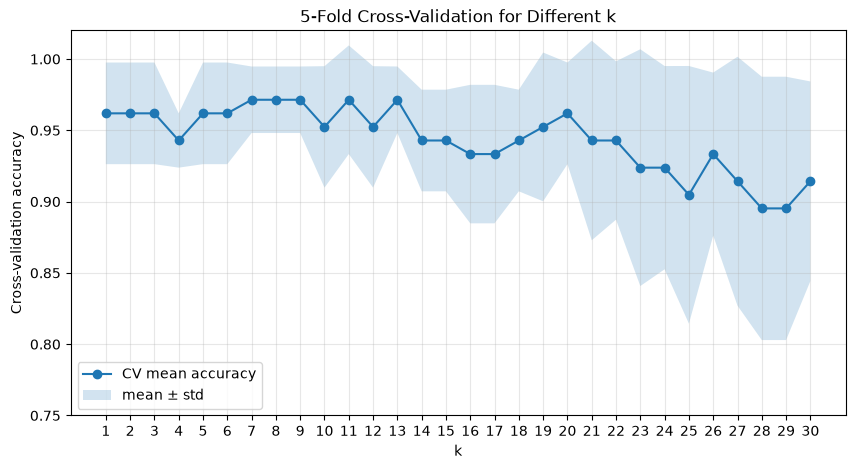

最高交叉验证平均准确率： 0.9714285714285715
对应的k： [11]


In [13]:
cv_mean_array = np.array(cv_mean_scores)
cv_std_array = np.array(cv_std_scores)

plt.figure(figsize=(10, 5))
plt.plot(k_values, cv_mean_array, marker="o", label="CV mean accuracy")
plt.fill_between(
    k_values,
    cv_mean_array - cv_std_array,
    cv_mean_array + cv_std_array,
    alpha=0.2,
    label="mean ± std"
)
plt.xlabel("k")
plt.ylabel("Cross-validation accuracy")
plt.title("5-Fold Cross-Validation for Different k")
plt.xticks(k_values)
plt.ylim(0.75, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

best_cv_mean = max(cv_mean_scores)
best_k_cv = [k for k, score in zip(k_values, cv_mean_scores) if score == best_cv_mean]
print("最高交叉验证平均准确率：", best_cv_mean)
print("对应的k：", best_k_cv)

### 3.2 分析

1. 交叉验证选择的k与单次划分是否相同？请引用自己的结果。

答：不同，交叉验证选择的k=11，准确率为0.97，与单次划分的k=5不同。

2. 为什么5折交叉验证通常比单次划分更稳定？

答：5折交叉验证可以使用不同的折作为测试数据，对于每个k都算5次之后取平均，过高或者过低的值会被平均掉。

3. 如果两个k的平均准确率非常接近，还可以参考什么？

答：还可以参考标准差，平均值接近时，更适合选择标准差更小的k。

## 4. 比较标准化前后的结果

KNN依赖样本之间的距离。如果不同特征的取值范围差异很大，范围较大的特征可能对距离产生更大影响。`Pipeline`可以保证标准化只在每一折的训练部分上拟合，避免数据泄露。

In [15]:
scaled_cv_mean_scores = []
scaled_cv_std_scores = []

for k in k_values:
    scaled_model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )
    scaled_scores = cross_val_score(
        scaled_model, X_train, y_train, cv=cv, scoring="accuracy"
    )
    # TODO：记录标准化后的平均准确率和标准差
    scaled_cv_mean_scores.append(scaled_scores.mean())
    scaled_cv_std_scores.append(scaled_scores.std())
print("标准化后的平均准确率：", scaled_cv_mean_scores)

标准化后的平均准确率： [np.float64(0.9428571428571428), np.float64(0.9428571428571428), np.float64(0.9523809523809523), np.float64(0.9428571428571428), np.float64(0.9333333333333333), np.float64(0.9428571428571428), np.float64(0.9619047619047618), np.float64(0.9714285714285713), np.float64(0.9523809523809523), np.float64(0.9523809523809523), np.float64(0.9523809523809523), np.float64(0.9428571428571428), np.float64(0.9428571428571428), np.float64(0.9428571428571428), np.float64(0.9238095238095237), np.float64(0.9142857142857143), np.float64(0.9047619047619048), np.float64(0.8952380952380953), np.float64(0.8952380952380953), np.float64(0.8857142857142858), np.float64(0.8857142857142858), np.float64(0.8857142857142858), np.float64(0.8761904761904763), np.float64(0.8857142857142858), np.float64(0.8761904761904763), np.float64(0.8761904761904763), np.float64(0.8761904761904763), np.float64(0.8761904761904763), np.float64(0.8761904761904763), np.float64(0.8761904761904763)]


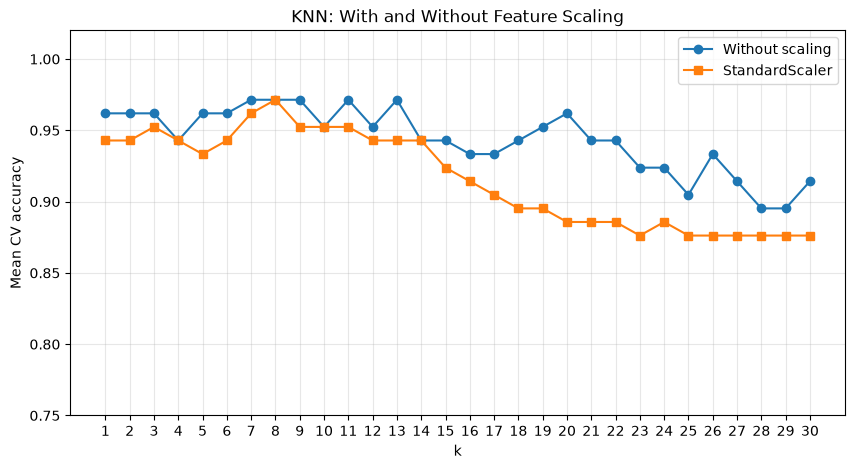

In [16]:
plt.figure(figsize=(10, 5))
plt.plot(k_values, cv_mean_scores, marker="o", label="Without scaling")
plt.plot(k_values, scaled_cv_mean_scores, marker="s", label="StandardScaler")
plt.xlabel("k")
plt.ylabel("Mean CV accuracy")
plt.title("KNN: With and Without Feature Scaling")
plt.xticks(k_values)
plt.ylim(0.75, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 4.1 分析

1. 标准化是否提高了本次实验的平均准确率？请引用具体结果。

答：没有，不标准化时最高的平均准确率时0.9714，标准化后最高的仍然是0.9714，出现在k=8时。

2. 标准化是否改变了较合适的k？

答：标准化改变了较合适的k。不标准化时，准确率最高的k为11，标准化后，最高的k为8。

3. 为什么KNN可能受到特征尺度的影响？

答：因为KNN靠样本之间的距离分类。某个特征的数值范围更大时，它在距离里占的比重就更大。鸢尾花数据集的花瓣长度和花瓣宽度范围差很多（长度从1到6.9，宽度从0.1到2.5）。如果不标准化，长度就更容易主导距离。

## 5. 观察决策边界

为了画出平面上的决策边界，这一部分只使用花瓣长度和花瓣宽度两个特征。绘图函数已经给出，不要求自己编写。

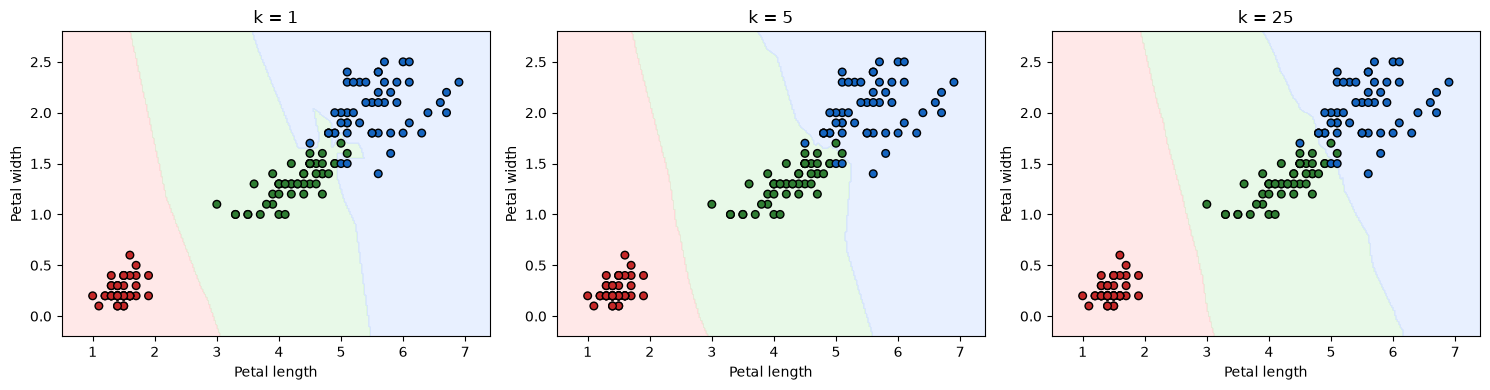

In [17]:
from matplotlib.colors import ListedColormap

def plot_knn_boundary(X_2d, y, k, ax):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_2d, y)

    x_min, x_max = X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5
    y_min, y_max = X_2d[:, 1].min() - 0.3, X_2d[:, 1].max() + 0.3
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid_points).reshape(xx.shape)

    background_cmap = ListedColormap(["#ffd6d6", "#d6f5d6", "#d6e4ff"])
    point_cmap = ListedColormap(["#c62828", "#2e7d32", "#1565c0"])
    ax.contourf(xx, yy, zz, alpha=0.55, cmap=background_cmap)
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap=point_cmap, edgecolor="black", s=30)
    ax.set_title(f"k = {k}")
    ax.set_xlabel("Petal length")
    ax.set_ylabel("Petal width")

X_2d = X[:, [2, 3]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axes, [1, 5, 25]):
    plot_knn_boundary(X_2d, y, k, ax)
plt.tight_layout()
plt.show()

### 5.1 决策边界分析

1. k=1、5、25中，哪个决策边界最曲折？

答：k=1

2. 随着k增大，决策边界发生了什么变化？这与过拟合、欠拟合有什么关系？

答：随着k增大，决策边界变得平滑。k=1时，容易受到个别噪声或者异常值的影响，可能出现过拟合，模型缺乏泛化的能力。k=25时，决策边界更平滑，可能忽略重要的局部特征，可能出现欠拟合，无法学习数据的规律。

3. 为什么这里的二维模型不能与前面使用全部四个特征的模型直接比较准确率？

答：这里的二维模型只使用了花瓣长度和花瓣宽度，而且是用了全部样本画出来的，没有留出测试集。前面的模型用了四个特征，而且准确率来自划分后的测试集。

## 6. 最终结论

请用一段完整文字总结本次实验。至少包括：

- 你最终认为哪个或哪些k较合适；
- 你的依据来自单次划分还是交叉验证；
- 标准化是否有用；
- 决策边界说明了什么。

**TODO：在此填写最终结论。**

我最终认为k=7，8，9比较合适。在单次训练集和测试集划分中，k=5的准确率最高，达到了0.97。但是在5折交叉验证时，k=7，8，9，11，13的平均准确率都为0.97。我认为交叉验证得出的结果更为合适，因为它减少了划分带来的偶然性的影响。在标准化时，标准化前后的最高准确率都为0.97，准确率没有随着标准化而改变。但是标准化改变了最好的k，k=8。随着k的增大，决策边界逐渐变得平滑。k=1时，模型易受到异常值的影响，造成过拟合。而k=25时，决策边界更为平滑，容易忽略局部细节和特征，导致欠拟合。

## 7. 拓展任务（至少完成一项）

至少完成一项：多次随机划分、距离加权、曼哈顿距离，或自拟问题。请写出问题、代码、结果和结论。只完成基础任务时，总分最高为85分。

**拓展问题：**
把KNN的距离从欧式距离还称曼哈顿距离后，5折交叉验证的平均准确率和较合适的k会不会发生变化

**实验与结论：**
曼哈顿距离的最高平均准确率是0.981，出现在k=9，11。而欧式距离的最高值时0.971，出现在k=7，8，9，11，13。使用曼哈顿距离之后，平均准确率小幅度提高了，较合适的k变化为k=9，11。

曼哈顿距离的最高平均准确率： 0.980952380952381
对应的k： [9, 11]


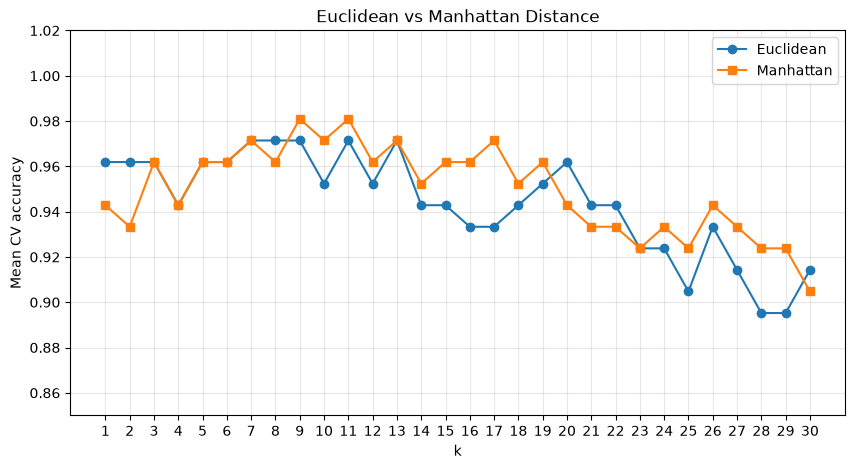

In [18]:
# 在这里编写至少一项拓展实验代码
manhattan_cv_mean_scores = []
manhattan_cv_std_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k, metric="manhattan")
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    manhattan_cv_mean_scores.append(scores.mean())
    manhattan_cv_std_scores.append(scores.std())

best_man_mean = max(manhattan_cv_mean_scores)
best_k_man = [k for k, score in zip(k_values, manhattan_cv_mean_scores) if score == best_man_mean]
print("曼哈顿距离的最高平均准确率：", best_man_mean)
print("对应的k：", best_k_man)

plt.figure(figsize=(10, 5))
plt.plot(k_values, cv_mean_scores, marker="o", label="Euclidean")
plt.plot(k_values, manhattan_cv_mean_scores, marker="s", label="Manhattan")
plt.xlabel("k")
plt.ylabel("Mean CV accuracy")
plt.title("Euclidean vs Manhattan Distance")
plt.xticks(k_values)
plt.ylim(0.85, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 8. AI使用说明

- 必做任务是否使用生成式AI：未使用
- 拓展任务是否使用生成式AI：使用AI进行了实验问题的提出
- AI帮助解决了什么问题：实验问题的提出
- 我采用了哪些建议或代码：实验问题的提出
- 我进行了哪些检查和修改：修改了实验问题的部分比较内容

如果没有使用AI，请明确写“未使用”。

## 提交前检查

- [ ] 已填写姓名和班级
- [ ] 已完成所有基础任务TODO
- [ ] 已完成至少一项拓展任务
- [ ] 已完成全部分析问题
- [ ] 已运行全部代码单元并保留输出
- [ ] Notebook从头到尾没有报错
- [ ] 文件名已改为 `班级_姓名_PA_KNN鸢尾花.ipynb`